# Transistors

In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from PyLTSpice.editor.spice_editor import SpiceEditor

import utils.ltspice_tools as lt
import utils.raw as rw

BASE_DIR = Path("..") / "models" / "transistors"

## Tranzystor NPN - Charakterystyki

In [4]:
asc_path = (BASE_DIR / "npn.asc").resolve()

spice = SpiceEditor(str(asc_path))
spice.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
spice.set_component_value("R1", "100k")
spice.set_component_value("V2", "3")
raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V2 0 10 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)

lt.clear_sim_outputs(asc_path)

In [5]:
df

,x,I(V2),Ic(Q1),I(R2),V(b),Is(Q1),V(c),I(R1),V(n002),V(n001),V2,Ie(Q1),Ib(Q1),I(V1)
0,0.0,1.008482e-11,1.010187e-11,-1.010291e-11,0.000001,0.0,10.000000,1.008482e-11,0.0,10.0,0.0,-1.753114e-14,-1.008482e-11,-1.010290e-11
1,0.1,9.869919e-12,1.081154e-11,-1.007049e-11,0.100001,0.0,10.000000,9.882336e-12,0.1,10.0,0.1,-9.430734e-13,-9.869924e-12,-1.081364e-11
2,0.2,9.320012e-12,4.900812e-11,-4.900986e-11,0.200001,0.0,10.000000,9.320015e-12,0.2,10.0,0.2,-3.968956e-11,-9.320017e-12,-4.900988e-11
3,0.3,-2.201335e-12,1.858029e-09,-1.858032e-09,0.300000,0.0,10.000000,-2.201313e-12,0.3,10.0,0.3,-1.860232e-09,2.201350e-12,-1.858030e-09
4,0.4,-4.604751e-10,8.716906e-08,-8.716894e-08,0.399954,0.0,9.999991,-4.604744e-10,0.4,10.0,0.4,-8.762954e-08,4.604751e-10,-8.716906e-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,9.6,-8.873012e-05,1.551112e-02,-1.551112e-02,0.726988,0.0,8.448889,-8.873012e-05,9.6,10.0,9.6,-1.559985e-02,8.873012e-05,-1.551112e-02
97,9.7,-8.972622e-05,1.566538e-02,-1.566538e-02,0.727377,0.0,8.433462,-8.972622e-05,9.7,10.0,9.7,-1.575511e-02,8.972622e-05,-1.566538e-02
98,9.8,-9.072236e-05,1.581929e-02,-1.581929e-02,0.727764,0.0,8.418071,-9.072236e-05,9.8,10.0,9.8,-1.591001e-02,9.072236e-05,-1.581929e-02
99,9.9,-9.171853e-05,1.597285e-02,-1.597285e-02,0.728147,0.0,8.402715,-9.171853e-05,9.9,10.0,9.9,-1.606457e-02,9.171853e-05,-1.597285e-02


### $I_B = f(U_{BE})$

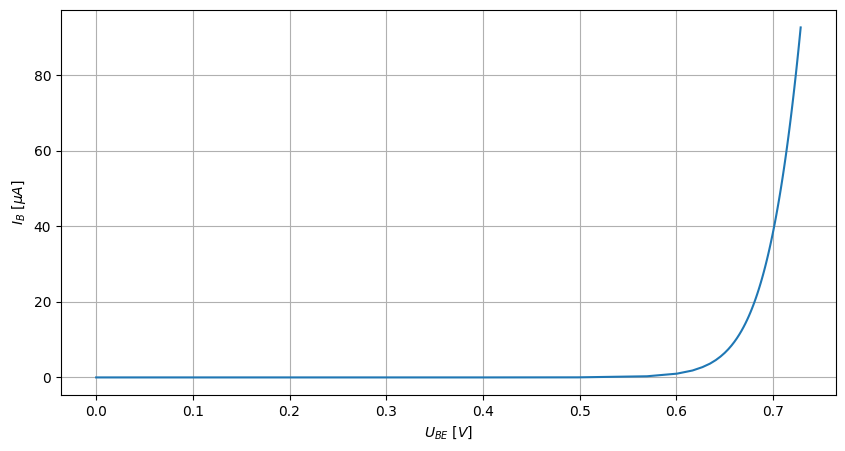

In [6]:
v_be = df["V(b)"]
i_b = df["Ib(Q1)"]*1e6


fig,ax = plt.subplots(figsize=(10, 5))
ax.plot(v_be, i_b)

ax.set_xlabel("$U_{BE} \  [V]$")
ax.set_ylabel("$I_B \ [\mu A]$")
ax.grid(True)

### $I_C = f(U_{CE})$

In [7]:
asc_path = (BASE_DIR / "npn.asc").resolve()

spice = SpiceEditor(str(asc_path))
spice.add_instructions(".MODEL BC547A NPN(IS=1.533E-14 ISE=7.932E-16 ISC=8.305E-14 XTI=3 BF=178.7 BR=8.628 IKF=0.1216 IKR=0.1121 XTB=1.5 VAF=69.7 VAR=44.7 VJE=0.4209 VJC=0.2 RE=0.6395 RC=0.6508 RB=1 RBM=1 IRB=1E-06 CJE=1.61E-11 CJC=4.388p XCJC=0.6193 FC=0.7762 NF=1.002 NR=1.004 NE=1.436 NC=1.207 MJE=0.3071 MJC=0.2793 TF=4.995E-10 TR=1m2 ITF=0.7021 VTF=3.523 XTF=139 EG=1.11 VCEO=50 ICRATING=100m MFG=PHILIPS)")
spice.add_instructions(".step param VB list 3 6 9")
spice.set_component_value("R1", "100k")
raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V1 0 10 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
df = rw.raw_to_dataframes_by_step(rr)

lt.clear_sim_outputs(asc_path)

In [8]:
df[0]

,x,I(V2),Ic(Q1),I(R2),V(b),Is(Q1),V(c),I(R1),V(n002),V(n001),Ie(Q1),V1,Ib(Q1),I(V1)
0,0.0,-0.000024,-0.000014,0.000014,0.588004,0.0,0.001358,-0.000024,3.0,0.0,-0.000011,0.0,0.000024,0.000014
1,0.1,-0.000024,0.000491,-0.000491,0.632926,0.0,0.050866,-0.000024,3.0,0.1,-0.000515,0.1,0.000024,-0.000491
2,0.2,-0.000023,0.001212,-0.001211,0.653680,0.0,0.078852,-0.000023,3.0,0.2,-0.001235,0.2,0.000023,-0.001212
3,0.3,-0.000023,0.001985,-0.001985,0.666213,0.0,0.101478,-0.000023,3.0,0.3,-0.002009,0.3,0.000023,-0.001985
4,0.4,-0.000023,0.002749,-0.002750,0.675139,0.0,0.124951,-0.000023,3.0,0.4,-0.002773,0.4,0.000023,-0.002749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96,9.6,-0.000023,0.004417,-0.004417,0.684936,0.0,9.158318,-0.000023,3.0,9.6,-0.004440,9.6,0.000023,-0.004417
97,9.7,-0.000023,0.004423,-0.004423,0.684940,0.0,9.257749,-0.000023,3.0,9.7,-0.004446,9.7,0.000023,-0.004423
98,9.8,-0.000023,0.004428,-0.004428,0.684943,0.0,9.357180,-0.000023,3.0,9.8,-0.004451,9.8,0.000023,-0.004428
99,9.9,-0.000023,0.004434,-0.004434,0.684947,0.0,9.456611,-0.000023,3.0,9.9,-0.004457,9.9,0.000023,-0.004434


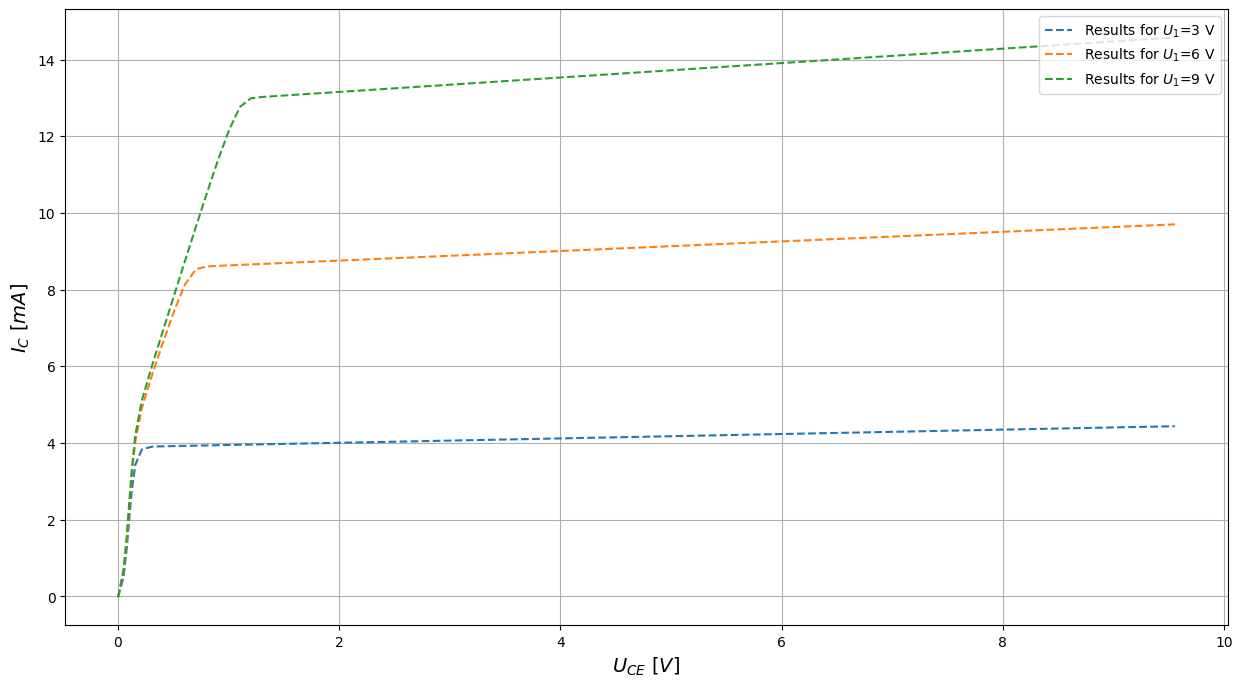

In [9]:
v_ce = df[0]["V(c)"]
i_c = {}
v_ce_pom = {}
i_c_pom = {}

for key, step in df.items():
    i_c[key] = step["Ic(Q1)"]*1e3

fig,ax = plt.subplots(figsize=(15, 8))
for step, i_c in i_c.items():
    ax.plot(v_ce, i_c, label=f"Results for $U_1$={3+3*step} V", linestyle="--")

ax.set_xlabel("$U_{CE} \  [V]$", fontdict={'size': 14})
ax.set_ylabel("$I_C \ [mA]$", fontdict={'size': 14})
ax.grid(True)
ax.legend(loc='upper right', bbox_to_anchor=(1, 1))
# ax.set_ylim(0,23)


## JFET

In [10]:
asc_path = (BASE_DIR / "jfet.asc").resolve()

spice = SpiceEditor(str(asc_path))
spice.add_instructions(".MODEL BF256B NJF(VTO=-3 BETA=1.09m BETATCE=-0.5 LAMBDA=2.31754E-2 RD=7.77648 RS=7.77648 CGS=2.00000p CGD=2.20000p PB=9.91494E-1 IS=2.59121E-16 XTI=3 AF=1 FC=0.5 N=1 NR=2 MFG=PHILIPS)")
raw_path = lt.run_sim(asc_path=asc_path, spice=spice,analysis_card=".dc V2 -5 0 0.1", output_dir=asc_path.parent, run_name=asc_path.stem, wait_seconds=50)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)

lt.clear_sim_outputs(asc_path)


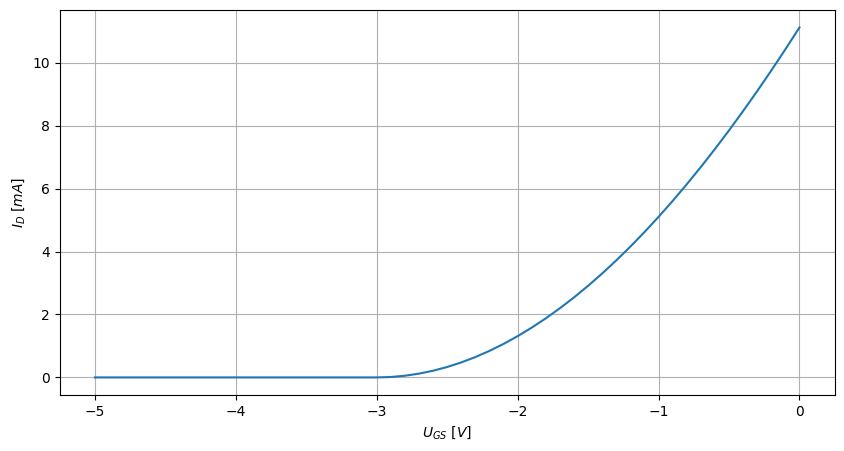

In [11]:
v_ce = df[("V(g)")]
i_d = df[("Id(J1)")] * 1e3

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(v_ce, i_d)

ax.set_xlabel("$U_{GS} \  [V]$")
ax.set_ylabel("$I_D \ [mA]$")
ax.grid(True)
